In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron as SklearnPerceptron
from sklearn.metrics import accuracy_score

### Single-layer perceptron class (Rosenblatt Algorithn)

In [8]:
class RosenblattPerceptron:
    def __init__(self, learning_rate=1.0, max_epochs=1000, normalize=True):
        self.learning_rate = learning_rate  # Set learning rate step hyperparameter
        self.max_epochs = max_epochs        # Set maximum number of epochs to prevent infinite loops
        self.normalize = normalize          # Flag indicating whether to normalize F_tilde vectors to unit length
        self.W_tilde = None                 # Initialize augmented weight vector W_tilde as None

    def fit(self, X, y):
        n_samples, n_features = X.shape  # Retrieve number of samples (n_samples) and feature count (n_features)
        
        # Create a column vector of -1s for the Bias neuron (threshold tau)
        bias_column = -np.ones((n_samples, 1))
        
        # Construct augmented feature vectors x_tilde = [x1, x2, -1] of dimension d+1
        X_tilde = np.hstack([X, bias_column])
        
        # Construct set Z (F_tilde): z_i = t_i * x_tilde_i, where t_i in {-1, 1}
        Z = X_tilde * y[:, np.newaxis]
        
        # Initialize initial approximation of augmented weight vector W_tilde with zeros
        self.W_tilde = np.zeros(n_features + 1)
        
        # Main training loop over epochs
        for epoch in range(self.max_epochs):
            errors = 0  # Reset misclassification counter for current epoch
            
            # Sequentially check every vector z_i in training set F_tilde
            for i in range(n_samples):
                z_i = Z[i]  # Extract current vector z_i
                
                # Check condition for correct classification: W_tilde^T * z_i > 0
                if np.dot(self.W_tilde, z_i) <= 0:
                    # If scalar product <= 0, sample is misclassified and weight modification is needed
                    if self.normalize:
                        norm_z = np.linalg.norm(z_i)  # Compute Euclidean norm (length) of vector z_i
                        phi = self.learning_rate / norm_z if norm_z != 0 else self.learning_rate  # phi = 1 / ||z_i||
                    else:
                        phi = self.learning_rate  # Learning step without normalization
                    
                    # Update weight coefficients: W_tilde = W_tilde + phi * z_i
                    self.W_tilde += phi * z_i
                    errors += 1  # Increment misclassification counter
            
            # Convergence check: if zero errors occurred during epoch, classes are fully separated
            if errors == 0:
                print(f"Rosenblatt algorithm converged successfully in {epoch + 1} epoch(s).")
                break  # Terminate training process early
        return self  # Return trained perceptron object instance

    def predict(self, X):
        n_samples = X.shape[0]  # Get number of test samples
        X_tilde = np.hstack([X, -np.ones((n_samples, 1))])  # Build augmented vectors [x1, x2, -1] for test set
        scores = np.dot(X_tilde, self.W_tilde)  # Compute inner products W_tilde^T * x_tilde
        predictions = np.where(scores >= 0, 1, -1)  # Apply step activation function sign()
        return predictions  # Return predicted class labels {-1, 1}

    @property
    def weights(self):
        return self.W_tilde[:-1]  # Extract primary weight vector W = [W1, W2]

    @property
    def tau(self):
        return self.W_tilde[-1]  # Extract learned threshold tau

### Data preparation

In [9]:
# Path to input dataset file
file_path = 'data/data06.csv'

# Read CSV file using semicolon ';' as separator and assign explicit column header names
data = pd.read_csv(file_path, sep=';', header=None, names=['x1', 'x2', 'target'])

# Extract feature matrix X from first two columns
X = data[['x1', 'x2']].values

# Convert ground-truth labels from {0, 1} to {-1, 1} format according to theoretical specification
y = np.where(data['target'].values == 0, -1, 1)

# Split dataset into training (70%) and testing (30%) subsets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

### Model training and test evaluation

In [10]:
# Instantiate custom implemented Rosenblatt perceptron
custom_perceptron = RosenblattPerceptron(learning_rate=1.0, max_epochs=1000, normalize=True)

# Train custom model on training subset (70%)
custom_perceptron.fit(X_train, y_train)

# Instantiate reference Scikit-Learn perceptron model
sklearn_perceptron = SklearnPerceptron(max_iter=1000, tol=1e-3, random_state=42)

# Train reference model on same training subset
sklearn_perceptron.fit(X_train, y_train)

# Generate predictions for test subset (30%) using both models
y_pred_custom = custom_perceptron.predict(X_test)
y_pred_sklearn = sklearn_perceptron.predict(X_test)

# Calculate accuracy scores for both custom and reference models
accuracy_custom = accuracy_score(y_test, y_pred_custom)
accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)

# Print final report metrics to console
print("\n" + "=" * 50)
print("CLASSIFICATION RESULTS FOR FILE:", file_path)
print("=" * 50)
print(f"Custom Perceptron Accuracy: {accuracy_custom * 100:.2f}%")
print(f"Scikit-Learn Perceptron Accuracy: {accuracy_sklearn * 100:.2f}%")
print(f"Learned Weight Vector W: {custom_perceptron.weights}")
print(f"Learned Threshold Tau: {custom_perceptron.tau}")

Rosenblatt algorithm converged successfully in 465 epoch(s).

CLASSIFICATION RESULTS FOR FILE: data/data06.csv
Custom Perceptron Accuracy: 96.67%
Scikit-Learn Perceptron Accuracy: 96.67%
Learned Weight Vector W: [17.45371516  3.43572939]
Learned Threshold Tau: 11.045399042887233


### Visualization

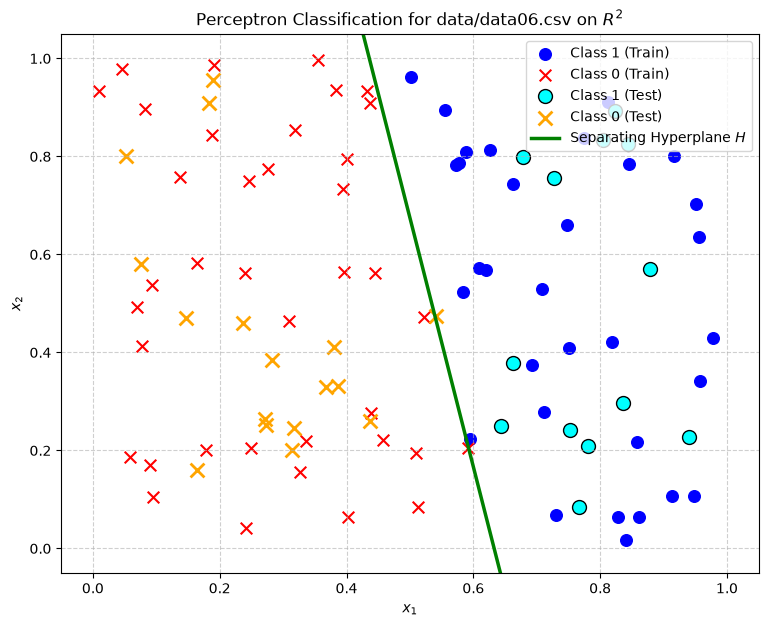

In [11]:
plt.figure(figsize=(9, 7))  # Create figure with 9x7 inch dimensions

# Plot training samples for Class +1 (blue dots)
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color='blue', label='Class 1 (Train)', marker='o', s=70)

# Plot training samples for Class -1 / 0 (red crosses)
plt.scatter(X_train[y_train == -1, 0], X_train[y_train == -1, 1], color='red', label='Class 0 (Train)', marker='x', s=70)

# Plot testing samples for Class +1 (cyan dots with black edge)
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], color='cyan', label='Class 1 (Test)', marker='o', s=100, edgecolors='black')

# Plot testing samples for Class -1 / 0 (orange crosses)
plt.scatter(X_test[y_test == -1, 0], X_test[y_test == -1, 1], color='orange', label='Class 0 (Test)', marker='x', s=100, linewidths=2)

# Generate range of x1 coordinates to plot decision boundary
x1_range = np.linspace(-0.05, 1.05, 200)

# Extract trained weight vector and threshold
W = custom_perceptron.weights
tau = custom_perceptron.tau

# Compute corresponding x2 coordinates via hyperplane line equation: W1*x1 + W2*x2 - tau = 0
if W[1] != 0:
    x2_range = (tau - W[0] * x1_range) / W[1]
    plt.plot(x1_range, x2_range, color='green', linewidth=2.5, label='Separating Hyperplane $H$')

plt.xlim(-0.05, 1.05)  # Set display bounds along X-axis
plt.ylim(-0.05, 1.05)  # Set display bounds along Y-axis
plt.title(f'Perceptron Classification for {file_path} on $R^2$')  # Set plot title
plt.xlabel('$x_1$')  # Label X-axis
plt.ylabel('$x_2$')  # Label Y-axis
plt.legend(loc='upper right')  # Add plot legend in upper right corner
plt.grid(True, linestyle='--', alpha=0.6)  # Enable grid lines
plt.show()  # Display final plot window